In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.table import Table
import ast
from astropy.table import Table

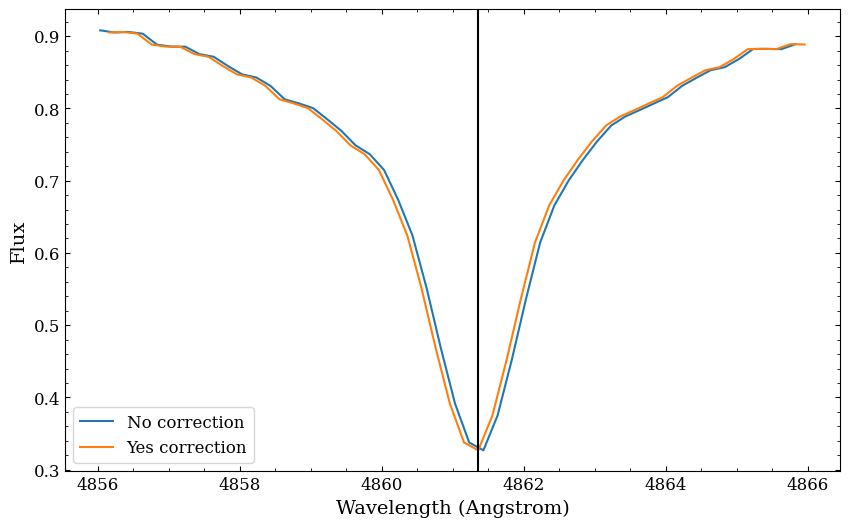

In [11]:
star_ncorr_data = Table.read('/data/misfit/benlowe/xshooter/p113/reduced_data/comb_spec_2/ra_0103-7050_s163/ra_0103-7050_s163_data.fits', hdu=1)
ncorr_wave = star_ncorr_data['wave']
ncorr_flux = star_ncorr_data['flux']
ncorr_flux_err = star_ncorr_data['flux_err']

star_ycorr_data = Table.read('/data/misfit/benlowe/xshooter/p113/reduced_data/comb_spec_3/ra_0103-7050_s163/ra_0103-7050_s163_data.fits', hdu=1)
ycorr_wave = star_ycorr_data['wave']
ycorr_flux = star_ycorr_data['flux']
ycorr_flux_err = star_ycorr_data['flux_err']


# Slicing the data to focus on the wavelength range of interest
ncorr_slice = star_ncorr_data[(star_ncorr_data['wave'] > 4856) & (star_ncorr_data['wave'] < 4866)]
ycorr_slice = star_ycorr_data[(star_ycorr_data['wave'] > 4856) & (star_ycorr_data['wave'] < 4866)]

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(ncorr_slice['wave'], ncorr_slice['flux'], label='No correction')
plt.plot(ycorr_slice['wave'], ycorr_slice['flux'], label='Yes correction')
plt.axvline(4861.35, color='black')
plt.xlabel('Wavelength (Angstrom)')
plt.ylabel('Flux')
plt.legend()


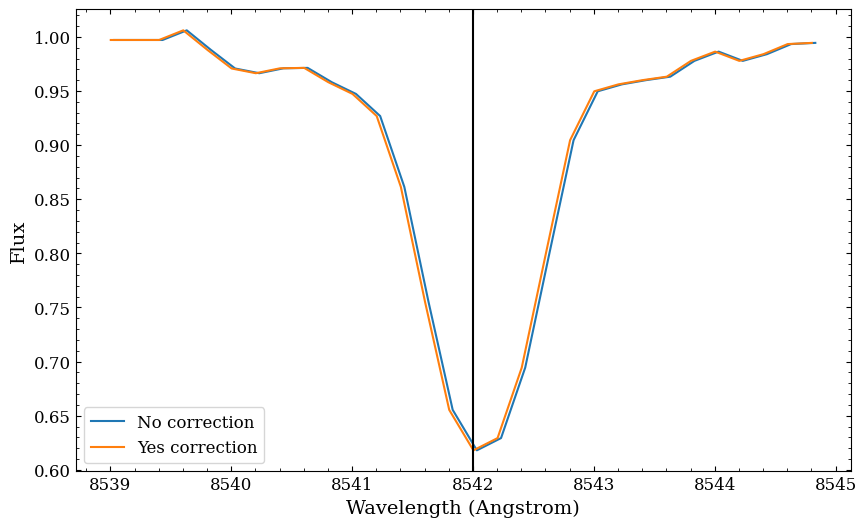

In [12]:
star_ncorr_data = Table.read('/data/misfit/benlowe/xshooter/p113/reduced_data/comb_spec_2/ra_0103-7050_s163/ra_0103-7050_s163_data.fits', hdu=2)
ncorr_wave = star_ncorr_data['wave']
ncorr_flux = star_ncorr_data['flux']
ncorr_flux_err = star_ncorr_data['flux_err']

star_ycorr_data = Table.read('/data/misfit/benlowe/xshooter/p113/reduced_data/comb_spec_3/ra_0103-7050_s163/ra_0103-7050_s163_data.fits', hdu=2)
ycorr_wave = star_ycorr_data['wave']
ycorr_flux = star_ycorr_data['flux']
ycorr_flux_err = star_ycorr_data['flux_err']


# Slicing the data to focus on the wavelength range of interest
ncorr_slice = star_ncorr_data[(star_ncorr_data['wave'] > 8539) & (star_ncorr_data['wave'] < 8545)]
ycorr_slice = star_ycorr_data[(star_ycorr_data['wave'] > 8539) & (star_ycorr_data['wave'] < 8545)]

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(ncorr_slice['wave'], ncorr_slice['flux'], label='No correction')
plt.plot(ycorr_slice['wave'], ycorr_slice['flux'], label='Yes correction')
plt.axvline(8542, color='black')
plt.xlabel('Wavelength (Angstrom)')
plt.ylabel('Flux')
plt.legend()


## Na-enhanced star

### Comparing LTE and NLTE Turbospectrum spectra to Korg

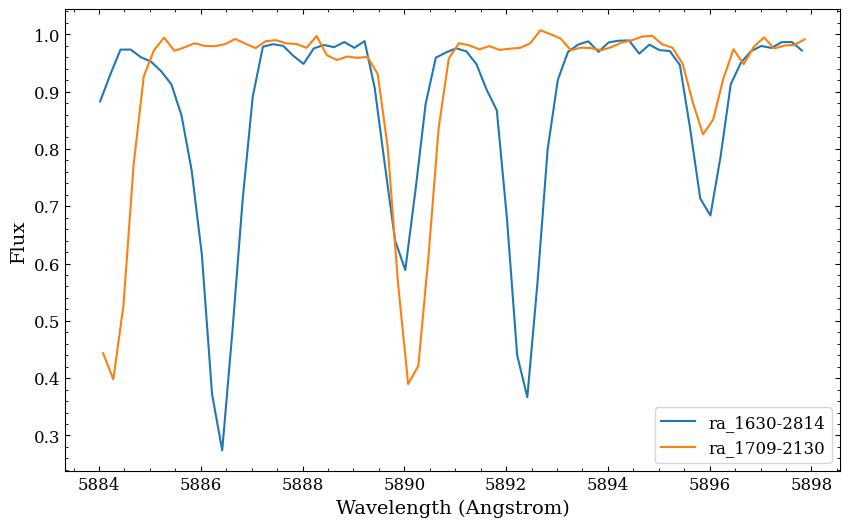

In [17]:
# Read in the data
star_ra1630_data = Table.read('/data/misfit/benlowe/xshooter/reduced_data/comb_spec_2/ra_1633-2814_s130/ra_1633-2814_s130_data.fits', hdu=2)
star_ra1709_data = Table.read('/data/misfit/benlowe/xshooter/reduced_data/comb_spec_2/ra_1709-2130_s102/ra_1709-2130_s102_data.fits', hdu=2)

# Slicing the data to focus on the wavelength range of interest
ra1630_slice = star_ra1630_data[(star_ra1630_data['wave'] > 5884) & (star_ra1630_data['wave'] < 5898)]
ra1709_slice = star_ra1709_data[(star_ra1709_data['wave'] > 5884) & (star_ra1709_data['wave'] < 5898)]

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(ra1630_slice['wave'], ra1630_slice['flux'], label='ra_1630-2814')
plt.plot(ra1709_slice['wave'], ra1709_slice['flux'], label='ra_1709-2130')
plt.xlabel('Wavelength (Angstrom)')
plt.ylabel('Flux')
plt.legend()

In [10]:
val_lte = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/tests/ra_1633-2814_s130_Na/ra_1633-2814_s130/Na_I/iter_1/0.csv')
val_lte

,#Generated using TurboSpectrum and TSFitPy wrapper
0,#date: 2025-09-15 12:02:01.144248
1,#spectrum_name: 0.spec
2,#teff: 5000
3,#logg: 0.9
4,#[Fe/H]: -2.0
...,...
50822,5949.992061102106 0.9993512722096299
50823,5949.994045825583 0.999357101038686
50824,5949.9960305497225 0.99936283507107
50825,5949.998015274535 0.999368474983708


(5884.0, 5898.0)

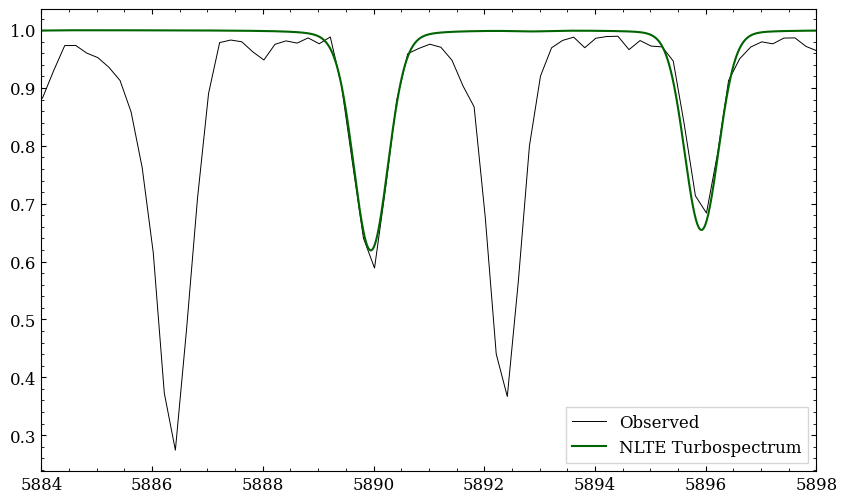

In [2]:
# Loading in Korg fit
ra_1630_df = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/tests/ra_1633-2814_s130_Na/ra_1633-2814_s130/Na_I/iter_1/fits_data/Na_5889.951_fit.csv')
val_lte_df = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/tests/ra_1633-2814_s130_Na/ra_1633-2814_s130/Na_I/iter_1/0.csv')
val_nlte_df = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/tests/ra_1633-2814_s130_Na/ra_1633-2814_s130/Na_I/iter_1/3.csv')

# Plotting 
plt.figure(figsize=(10, 6))
plt.plot(ra_1630_df['wave'], ra_1630_df['flux'], color='black', linewidth=0.7, label='Observed')
# plt.plot(ra_1630_df['wave'], ra_1630_df['best_fit'], color='chocolate', label='Korg')
# plt.plot(val_lte_df['Wavelength'], val_lte_df['Normalised_flux'], color='darkblue', label='LTE Turbospectrum')
plt.plot(val_nlte_df['Wavelength'], val_nlte_df['Normalised_flux'], color='darkgreen', label='NLTE Turbospectrum')
plt.legend(fancybox=False)
plt.xlim(5884, 5898)

### Looking at the 8183 and 8194A lines

There is lots of telluric lines, so will also plot the individual OBs to be able to accurately pin-point where the Na absorption is located

In [2]:
def spec_shift(waves, vel):
    """
    Performs radial shift on spectra.

    Parameters
    ----------
    waves : ndarray
        Wavelength array being shifted.

    vel : float
        Radial velocity value being used to perform the correction.

    Returns
    -------
    waves_shifted : ndarray
        Velocity-corrected wavelength array.
    """
    c = 299792.458

    # COMPUTING SHIFT IN LOG SPACE
    shift = np.log(1 + vel / c)

    # TRANSFORMING SHIFTED AXIS INTO WAVELENGTH SPACE
    waves_shifted = np.exp(np.log(waves) - shift)

    return waves_shifted

In [4]:
ref_star = Table.read('/data/misfit/benlowe/xshooter/p113/reduced_data/comb_spec_2/ra_1752-4300_s6/ra_1752-4300_s6_data.fits', hdu=2)
ref_wave = ref_star['wave']
ref_flux = ref_star['flux']
ref_flux_err = ref_star['flux_err']

# Shifting reference star by
ref_wave_shift = spec_shift(ref_wave, -130.1)

wave_mask = np.where((ref_wave_shift > 8175) & (ref_wave_shift < 8202))[0]
ref_wave = ref_wave_shift[wave_mask]
ref_flux = ref_flux[wave_mask]
ref_flux_err = ref_flux_err[wave_mask]

ob_star = Table.read('/data/misfit/benlowe/xshooter/p113/reduced_data/comb_spec_2/ra_1633-2814_s130/ra_1633-2814_s130_data.fits', hdu=2)
ob_wave = ob_star['wave']
ob_flux = ob_star['flux']
ob_flux_err = ob_star['flux_err']

wave_mask = np.where((ob_wave > 8175) & (ob_wave < 8202))[0]
ob_wave = ob_wave[wave_mask]
ob_flux = ob_flux[wave_mask]
ob_flux_err = ob_flux_err[wave_mask]


In [12]:
ob_wave

8175.151533394064
8175.3514050759695
8175.5512767578775
8175.751148439781
8175.951020121689
8176.150891803608
8176.350763485518
8176.550635167426
8176.7505068493265
8176.950378531243
8177.150250213138


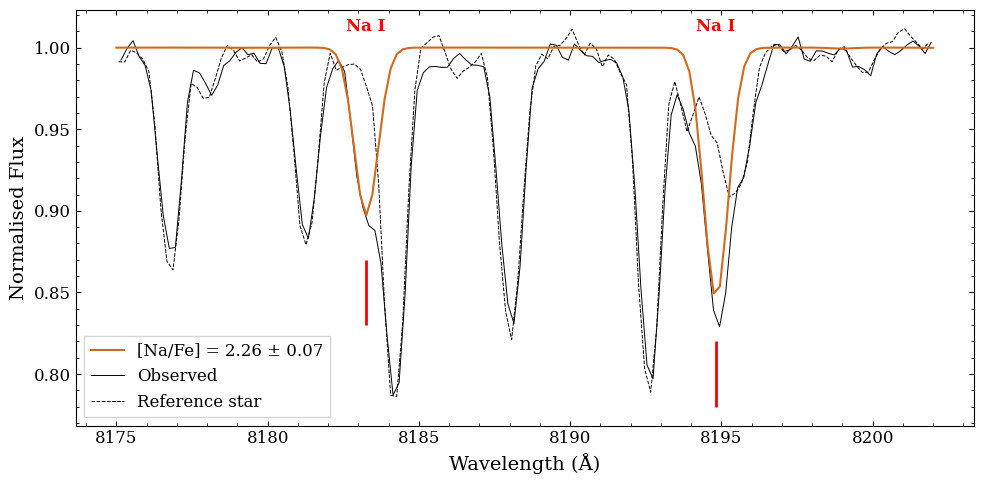

In [19]:
# Loading in the synthetic spectra
ra1633_synth_df = pd.read_csv('/data/misfit/benlowe/xshooter/p113/korg_data/na_ra1633-2814_s130/ra_1633-2814_s130_na8183_8195/Na_I/synth_specs/2.28_spec.csv')

plt.figure(figsize=(10, 5))
plt.plot(ra1633_synth_df['synth_wave'], (ra1633_synth_df['synth_flux'] / np.max(ra1633_synth_df['synth_flux'])), label='[Na/Fe] = 2.26 ± 0.07', color='chocolate', zorder=10)
plt.plot(ob_wave, (ob_flux * 1.01), color='black', linewidth=0.7, label='Observed')
# # plt.plot(ref_wave, (ref_flux * 1.5) - 0.48, color='black', linestyle='--', linewidth=0.7, label='Reference Star')
plt.plot(ref_wave, (ref_flux * 0.8) + 0.21, color='black', linestyle='--', linewidth=0.7, label='Reference star')

plt.vlines(x=8183.256, ymin=0.83, ymax=0.87, color='red', linewidth=2)
plt.vlines(x=8194.824, ymin=0.78, ymax=0.82, color='red', linewidth=2)
plt.text(8183.256, 1.01, 'Na I', color='red', fontsize=12, ha='center', fontweight='bold')
plt.text(8194.824, 1.01, 'Na I', color='red', fontsize=12, ha='center', fontweight='bold')



plt.legend(fancybox=False)
plt.xlabel('Wavelength (Å)')
plt.ylabel('Normalised Flux')
plt.tight_layout()

plt.savefig('/data/misfit/benlowe/xshooter/p113/results/star_abunds/ra_1633-2814_s130_Na_8183A_8194A_v2.png', dpi=300, bbox_inches='tight')
plt.savefig('/data/misfit/benlowe/xshooter/p113/results/star_abunds/ra_1633-2814_s130_Na_8183A_8194A_v2.pdf', dpi=300, bbox_inches='tight')

### Looking at the 5889 and 5895A lines

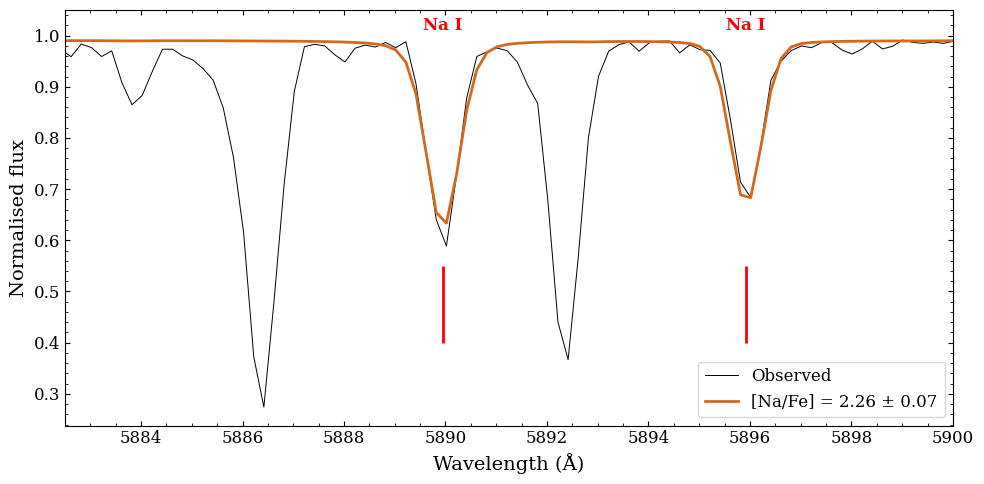

In [18]:
# Loading in the synthetic and observed datasets
data_df = pd.read_csv("/data/misfit/benlowe/xshooter/p113/korg_data/tests/ra_1633-2814_s130_Na/ra_1633-2814_s130/Na_I/iter_1/Na_results.csv")

obs_wave = ast.literal_eval(data_df['obs_wave'].to_numpy()[0])[0]
obs_flux = ast.literal_eval(data_df['obs_flux'].to_numpy()[0])[0]
bestfit_wave = ast.literal_eval(data_df['fit_wave'].to_numpy()[0])[0]
bestfit_flux = ast.literal_eval(data_df['fit_flux'].to_numpy()[0])[0]
# obs_flux = data_df['flux']
# fit_flux = data_df['best_fit']


plt.figure(figsize=[10,5])
plt.plot(obs_wave, obs_flux, color='black', linewidth=0.7, label='Observed')
plt.plot(bestfit_wave, bestfit_flux, color='chocolate', label='[Na/Fe] = 2.26 ± 0.07', linewidth=2)
plt.vlines(x=5889.951, ymin=0.4, ymax=0.55, color='red', linewidth=2)
plt.vlines(x=5895.924, ymin=0.4, ymax=0.55, color='red', linewidth=2)
plt.text(5889.951, 1.01, 'Na I', color='red', fontsize=12, ha='center', fontweight='bold')
plt.text(5895.924, 1.01, 'Na I', color='red', fontsize=12, ha='center', fontweight='bold')

plt.xlabel('Wavelength (Å)')
plt.ylabel('Normalised flux')
plt.ylim(top=1.05)
plt.xlim(left=5882.5, right=5900)
plt.legend(fancybox=True)
plt.tight_layout()
plt.savefig('/data/misfit/benlowe/xshooter/p113/results/star_abunds/ra_1633-2814_s130_Na_fit_v2.png', dpi=300, bbox_inches='tight')
plt.savefig('/data/misfit/benlowe/xshooter/p113/results/star_abunds/ra_1633-2814_s130_Na_fit_v2.pdf', dpi=300, bbox_inches='tight')

### Looking at the 5682.65 and 5688.22A lines

In [9]:
ob_star = Table.read('/data/misfit/benlowe/xshooter/reduced_data/p113_data/comb_spec_2/ra_1633-2814_s130/ra_1633-2814_s130_data.fits', hdu=2)
ob_wave = ob_star['wave']
ob_flux = ob_star['flux']
ob_flux_err = ob_star['flux_err']

wave_mask = np.where((ob_wave > 5675) & (ob_wave < 5695))[0]
ob_wave = ob_wave[wave_mask]
ob_flux = ob_flux[wave_mask]
ob_flux_err = ob_flux_err[wave_mask]


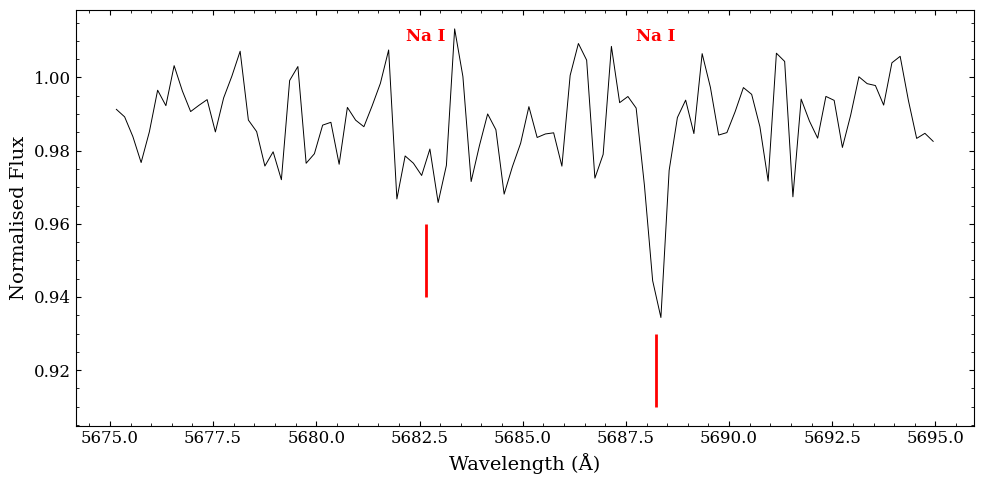

In [19]:
# Loading in the synthetic spectra
ra1633_synth_df = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/na_ra1633-2814_s130/ra_1633-2814_s130/Na_I/synth_specs/2.28_spec.csv')

plt.figure(figsize=(10, 5))
# plt.plot(ra1633_synth_df['synth_wave'], (ra1633_synth_df['synth_flux'] / np.max(ra1633_synth_df['synth_flux'])), label='[Na/Fe] = 2.28 ± 0.07', color='chocolate', zorder=10)
plt.plot(ob_wave, (ob_flux * 1.01), color='black', linewidth=0.7, label='Observed')
# plt.plot(ref_wave, (ref_flux * 1.5) - 0.48, color='black', linestyle='--', linewidth=0.7, label='Reference Star')
# plt.plot(ref_wave, (ref_flux * 0.8) + 0.21, color='black', linestyle='--', linewidth=0.7, label='Reference star')

plt.vlines(x=5682.65, ymin=0.94, ymax=0.96, color='red', linewidth=2)
plt.vlines(x=5688.22, ymin=0.91, ymax=0.93, color='red', linewidth=2)
plt.text(5682.65, 1.01, 'Na I', color='red', fontsize=12, ha='center', fontweight='bold')
plt.text(5688.22, 1.01, 'Na I', color='red', fontsize=12, ha='center', fontweight='bold')



# plt.legend(fancybox=False)
plt.xlabel('Wavelength (Å)')
plt.ylabel('Normalised Flux')
plt.tight_layout()

plt.savefig('/data/misfit/benlowe/xshooter/results/star_abunds/ra_1633-2814_s130_Na_5682A_5688A.png', dpi=300, bbox_inches='tight')
plt.savefig('/data/misfit/benlowe/xshooter/results/star_abunds/ra_1633-2814_s130_Na_5682A_5688A.pdf', dpi=300, bbox_inches='tight')

### Looking at the 6154.22 and 6160.75A lines

In [20]:
ob_star = Table.read('/data/misfit/benlowe/xshooter/reduced_data/p113_data/comb_spec_2/ra_1633-2814_s130/ra_1633-2814_s130_data.fits', hdu=2)
ob_wave = ob_star['wave']
ob_flux = ob_star['flux']
ob_flux_err = ob_star['flux_err']

wave_mask = np.where((ob_wave > 6148) & (ob_wave < 6166))[0]
ob_wave = ob_wave[wave_mask]
ob_flux = ob_flux[wave_mask]
ob_flux_err = ob_flux_err[wave_mask]


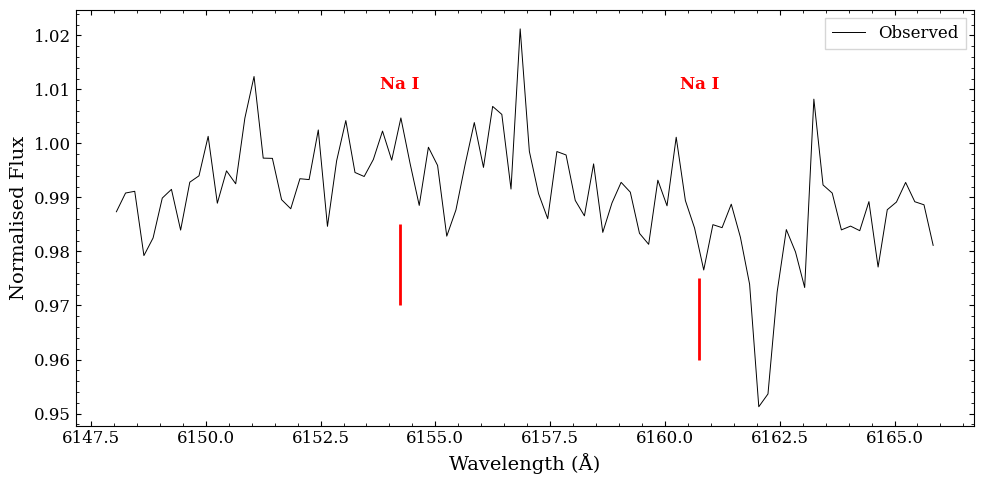

In [24]:
# # Loading in the synthetic spectra
# ra1633_synth_df = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/na_ra1633-2814_s130/ra_1633-2814_s130/Na_I/synth_specs/2.28_spec.csv')

plt.figure(figsize=(10, 5))
# plt.plot(ra1633_synth_df['synth_wave'], (ra1633_synth_df['synth_flux'] / np.max(ra1633_synth_df['synth_flux'])), label='[Na/Fe] = 2.28 ± 0.07', color='chocolate', zorder=10)
plt.plot(ob_wave, (ob_flux * 1.01), color='black', linewidth=0.7, label='Observed')
# plt.plot(ref_wave, (ref_flux * 1.5) - 0.48, color='black', linestyle='--', linewidth=0.7, label='Reference Star')
# plt.plot(ref_wave, (ref_flux * 0.8) + 0.21, color='black', linestyle='--', linewidth=0.7, label='Reference star')

plt.vlines(x=6154.22, ymin=0.97, ymax=0.985, color='red', linewidth=2)
plt.vlines(x=6160.75, ymin=0.975, ymax=0.96, color='red', linewidth=2)
plt.text(6154.22, 1.01, 'Na I', color='red', fontsize=12, ha='center', fontweight='bold')
plt.text(6160.75, 1.01, 'Na I', color='red', fontsize=12, ha='center', fontweight='bold')



plt.legend(fancybox=False)
plt.xlabel('Wavelength (Å)')
plt.ylabel('Normalised Flux')
plt.tight_layout()

plt.savefig('/data/misfit/benlowe/xshooter/results/star_abunds/ra_1633-2814_s130_Na_6154A_6160A.png', dpi=300, bbox_inches='tight')
plt.savefig('/data/misfit/benlowe/xshooter/results/star_abunds/ra_1633-2814_s130_Na_6154A_6160A.pdf', dpi=300, bbox_inches='tight')

### Looking at the K lines

In [7]:
ref_star = Table.read('/data/misfit/benlowe/xshooter/p113/reduced_data/comb_spec_2/ra_1752-4300_s6/ra_1752-4300_s6_data.fits', hdu=2)
ref_wave = ref_star['wave']
ref_flux = ref_star['flux']
ref_flux_err = ref_star['flux_err']

# Shifting reference star by
ref_wave_shift = spec_shift(ref_wave, -130.1)

wave_mask = np.where((ref_wave_shift > 7655) & (ref_wave_shift < 7705))[0]
ref_wave = ref_wave_shift[wave_mask]
ref_flux = ref_flux[wave_mask]
ref_flux_err = ref_flux_err[wave_mask]

ob_star = Table.read('/data/misfit/benlowe/xshooter/p113/reduced_data/comb_spec_2/ra_1633-2814_s130/ra_1633-2814_s130_data.fits', hdu=2)
ob_wave = ob_star['wave']
ob_flux = ob_star['flux']
ob_flux_err = ob_star['flux_err']

wave_mask = np.where((ob_wave > 7655) & (ob_wave < 7705))[0]
ob_wave = ob_wave[wave_mask]
ob_flux = ob_flux[wave_mask]
ob_flux_err = ob_flux_err[wave_mask]


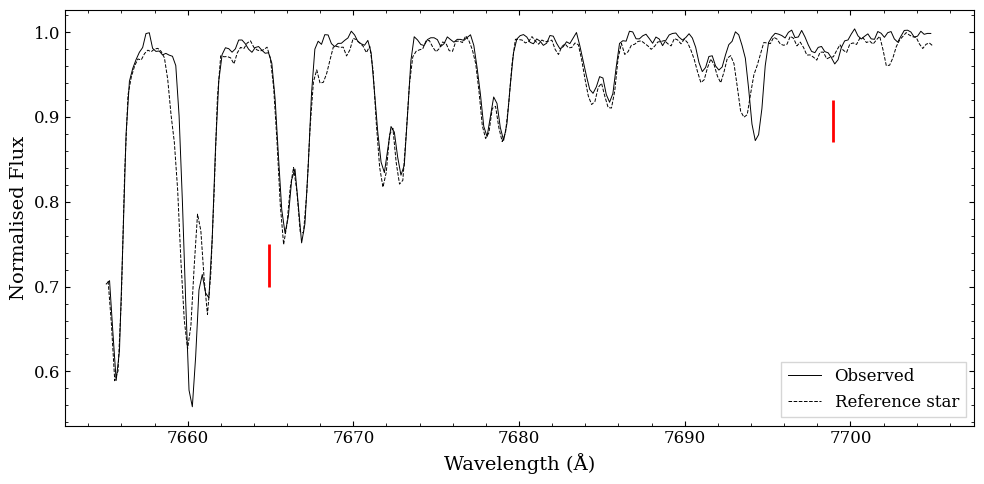

In [13]:
# # Loading in the synthetic spectra
# ra1633_synth_df = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/na_ra1633-2814_s130/ra_1633-2814_s130/Na_I/synth_specs/2.28_spec.csv')

plt.figure(figsize=(10, 5))
# plt.plot(ra1633_synth_df['synth_wave'], (ra1633_synth_df['synth_flux'] / np.max(ra1633_synth_df['synth_flux'])), label='[Na/Fe] = 2.28 ± 0.07', color='chocolate', zorder=10)
plt.plot(ob_wave, (ob_flux * 1.01), color='black', linewidth=0.7, label='Observed')
# plt.plot(ref_wave, (ref_flux * 1.5) - 0.48, color='black', linestyle='--', linewidth=0.7, label='Reference Star')
plt.plot(ref_wave, (ref_flux * 0.93) + 0.07, color='black', linestyle='--', linewidth=0.7, label='Reference star')

plt.vlines(x=7664.899, ymin=0.7, ymax=0.75, color='red', linewidth=2)
plt.vlines(x=7698.965, ymin=0.87, ymax=0.92, color='red', linewidth=2)
# plt.text(8183.256, 1.01, 'Na I', color='red', fontsize=12, ha='center', fontweight='bold')
# plt.text(8194.824, 1.01, 'Na I', color='red', fontsize=12, ha='center', fontweight='bold')

plt.legend(fancybox=False)
plt.xlabel('Wavelength (Å)')
plt.ylabel('Normalised Flux')
plt.tight_layout()

# plt.savefig('/data/misfit/benlowe/xshooter/results/star_abunds/ra_1633-2814_s130_Na_8183A_8194A.png', dpi=300, bbox_inches='tight')
# plt.savefig('/data/misfit/benlowe/xshooter/results/star_abunds/ra_1633-2814_s130_Na_8183A_8194A.pdf', dpi=300, bbox_inches='tight')

## N-depleted star

For ra_1658-2454_s22

In [ ]:
# For [N/Fe] = -0.67 dex
ra1658_m067 = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/synths_v2/ra_1658-2454_s22/N_I/obs/line_3360.22/spectra/-0.67_spec.csv')
ra1658_m067_fitflux = np.array(ast.literal_eval(ra1658_m067['fit_flux'].to_numpy()[0]))
ra1658_m067_fitwave = np.array(ast.literal_eval(ra1658_m067['fit_wave'].to_numpy()[0]))

# For observed
ra1658_obsflux = np.array(ast.literal_eval(ra1658_m067['obs_flux'].to_numpy()[0]))
ra1658_obsfluxerr = np.array(ast.literal_eval(ra1658_m067['obs_flux_err'].to_numpy()[0]))
ra1658_obswave = np.array(ast.literal_eval(ra1658_m067['obs_wave'].to_numpy()[0]))

# For [N/Fe] = -1.13 dex (main)
ra1658_m113 = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/synths_v2/ra_1658-2454_s22/N_I/obs/line_3360.22/spectra/-1.13_spec.csv')
ra1658_m113_fitflux = np.array(ast.literal_eval(ra1658_m113['fit_flux'].to_numpy()[0]))
ra1658_m113_fitwave = np.array(ast.literal_eval(ra1658_m113['fit_wave'].to_numpy()[0]))

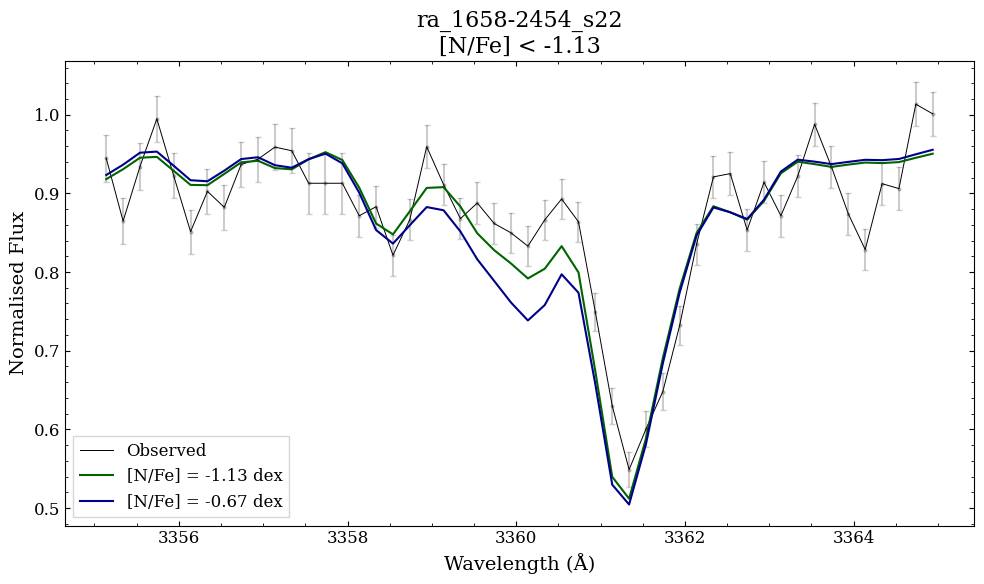

In [29]:
waveslice = np.where((ra1658_obswave > 3355) & (ra1658_obswave < 3365))

plt.figure(figsize=(10, 6))
plt.plot(ra1658_obswave[waveslice], ra1658_obsflux[waveslice], color='black', linewidth=0.7, label='Observed')
plt.errorbar(ra1658_obswave[waveslice], ra1658_obsflux[waveslice], yerr=ra1658_obsfluxerr[waveslice], fmt='o', 
             color='black', markersize=2, capsize=2, alpha=0.2)
plt.plot(ra1658_m113_fitwave[waveslice], ra1658_m113_fitflux[waveslice], color='darkgreen', label='[N/Fe] = -1.13 dex')
plt.plot(ra1658_m067_fitwave[waveslice], ra1658_m067_fitflux[waveslice], color='darkblue', label='[N/Fe] = -0.67 dex')

plt.title('ra_1658-2454_s22\n[N/Fe] < -1.13')
plt.legend(fancybox=False)
plt.xlabel('Wavelength (Å)')
plt.ylabel('Normalised Flux')
plt.tight_layout()

plt.savefig('/data/misfit/benlowe/xshooter/results/star_abunds/ra1658_nfe_-0.67_and_-1.13.png', dpi=300, bbox_inches='tight')

For ra_1853-3255_s45

In [26]:
# For [N/Fe] = -0.67 dex
ra1853_m067 = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/synths_v2/ra_1853-3255_s45/N_I/obs/line_3360.22/spectra/-0.67_spec.csv')
ra1853_m067_fitflux = np.array(ast.literal_eval(ra1853_m067['fit_flux'].to_numpy()[0]))
ra1853_m067_fitwave = np.array(ast.literal_eval(ra1853_m067['fit_wave'].to_numpy()[0]))

# For observed
ra1853_obsflux = np.array(ast.literal_eval(ra1853_m067['obs_flux'].to_numpy()[0]))
ra1853_obsfluxerr = np.array(ast.literal_eval(ra1853_m067['obs_flux_err'].to_numpy()[0]))
ra1853_obswave = np.array(ast.literal_eval(ra1853_m067['obs_wave'].to_numpy()[0]))

# For [N/Fe] = -1.13 dex (main)
ra1853_m113 = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/synths_v2/ra_1853-3255_s45/N_I/obs/line_3360.22/spectra/-1.13_spec.csv')
ra1853_m113_fitflux = np.array(ast.literal_eval(ra1853_m113['fit_flux'].to_numpy()[0]))
ra1853_m113_fitwave = np.array(ast.literal_eval(ra1853_m113['fit_wave'].to_numpy()[0]))


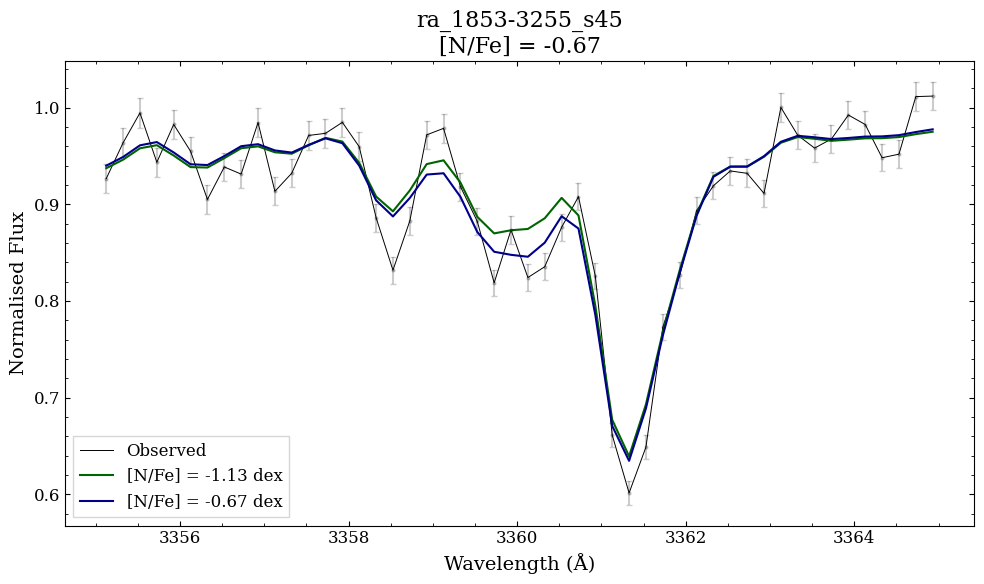

In [30]:
waveslice = np.where((ra1853_obswave > 3355) & (ra1853_obswave < 3365))

plt.figure(figsize=(10, 6))
plt.plot(ra1853_obswave[waveslice], ra1853_obsflux[waveslice], color='black', linewidth=0.7, label='Observed')
plt.errorbar(ra1853_obswave[waveslice], ra1853_obsflux[waveslice], yerr=ra1853_obsfluxerr[waveslice], fmt='o', 
             color='black', markersize=2, capsize=2, alpha=0.2)
plt.plot(ra1853_m113_fitwave[waveslice], ra1853_m113_fitflux[waveslice], color='darkgreen', label='[N/Fe] = -1.13 dex')
plt.plot(ra1853_m067_fitwave[waveslice], ra1853_m067_fitflux[waveslice], color='darkblue', label='[N/Fe] = -0.67 dex')

plt.title('ra_1853-3255_s45\n[N/Fe] = -0.67')
plt.legend(fancybox=False)
plt.xlabel('Wavelength (Å)')
plt.ylabel('Normalised Flux')
plt.tight_layout()

plt.savefig('/data/misfit/benlowe/xshooter/results/star_abunds/ra1853_nfe_-0.67_and_-1.13.png', dpi=300, bbox_inches='tight')